# 12 — Graph analytics (Bab 6)

Dua graph dibangun dari metadata bersih A1 (`/datalake/processed/metadata`) dan dianalisis dengan **GraphFrames**, library graph terdistribusi di atas Spark:

| Graph | Vertex | Edge | Dipakai untuk |
|---|---|---|---|
| **G1** kejadian–stasiun | kejadian (ComCat + Exotic) dan stasiun | stasiun merekam kejadian | degree, connected components |
| **G2** stasiun–stasiun | stasiun | dua stasiun merekam kejadian yang sama; bobot = jumlah kejadian bersama | PageRank, label propagation, triangle count |

Noise tidak punya kejadian, sehingga tidak masuk graph. Lokasi stasiun dipakai untuk peta dan analisis, bukan sebagai input model.

In [1]:
import sys, os, time
sys.path.insert(0, os.path.abspath('../src'))
from common import *
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pyspark import StorageLevel
from pyspark.sql import functions as F

pd.set_option('display.width', 200, 'display.max_columns', 30)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
spark = spark_session('a2_graph', packages='io.graphframes:graphframes-spark3_2.12:0.12.3')
spark.sparkContext.setCheckpointDir(os.path.expanduser('~/pnwml-data/tmp/graph-ckpt'))
from graphframes import GraphFrame

meta = spark.read.parquet(f'{HDFS}{PROCESSED}/metadata')
GRAPH = '/datalake/graph'
EVENTS = ['earthquake', 'explosion', 'surface_event']
timings = []

def timed(step, fn):
    t0 = time.time()
    out = fn()
    timings.append((step, round(time.time() - t0, 1)))
    return out

:: loading settings :: url = jar:file:/Users/axelnakata/Documents/BigData-Earthquake/.venv/lib/python3.11/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /Users/axelnakata/.ivy2/cache
The jars for the packages stored in: /Users/axelnakata/.ivy2/jars
io.graphframes#graphframes-spark3_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-2b005ad5-ad2b-4551-a088-dc15528a3975;1.0
	confs: [default]
	found io.graphframes#graphframes-spark3_2.12;0.12.3 in central
	found io.graphframes#graphframes-graphx-spark3_2.12;0.12.3 in central
	found org.apache.datasketches#datasketches-java;6.2.0 in central
	found org.apache.datasketches#datasketches-memory;3.0.2 in central
:: resolution report :: resolve 65ms :: artifacts dl 3ms
	:: modules in use:
	io.graphframes#graphframes-graphx-spark3_2.12;0.12.3 from central in [default]
	io.graphframes#graphframes-spark3_2.12;0.12.3 from central in [default]
	org.apache.datasketches#datasketches-java;6.2.0 from central in [default]
	org.apache.datasketches#datasketches-memory;3.0.2 from central in [default]
	----------------------------------------

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/11 12:50:56 WARN SparkConf: Note that spark.local.dir will be overridden by the value set by the cluster manager (via SPARK_LOCAL_DIRS in mesos/standalone/kubernetes and LOCAL_DIRS in YARN).


## 6.1 Pengembangan graph
### G1: kejadian–stasiun
- Vertex kejadian: `ev:dataset:event_id` (awalan dataset supaya ID ComCat dan Exotic tidak tercampur), atribut kelas.
- Vertex stasiun: `st:jaringan.stasiun`, atribut jaringan dan rata-rata lintang/bujur/elevasi.
- Edge: pasangan unik (kejadian, stasiun), atribut `recordings` = jumlah rekaman (satu stasiun bisa punya lebih dari satu sensor).

In [2]:
sh(f'hdfs dfs -mkdir -p {GRAPH} && hdfs dfs -chgrp engineer {GRAPH} && hdfs dfs -chmod 770 {GRAPH}')
sh(f'hdfs dfs -setfacl -m group:scientist:r-x,default:group:engineer:rwx,default:group:scientist:r-x,default:other::--- {GRAPH}')

rec = (meta.filter('event_id IS NOT NULL')
       .select(F.concat_ws(':', F.lit('ev'), 'dataset', 'event_id').alias('event'),
               F.concat_ws('.', 'station_network_code', 'station_code').alias('station_name'),
               'label', 'station_network_code', 'station_latitude_deg', 'station_longitude_deg', 'station_elevation_m')
       .withColumn('station', F.concat(F.lit('st:'), 'station_name')))

ev_v = (rec.groupBy(F.col('event').alias('id'))
        .agg(F.first('label').alias('label'), F.countDistinct('label').alias('n_labels'))
        .withColumn('kind', F.lit('event')))
st_v = (rec.groupBy(F.col('station').alias('id'))
        .agg(F.first('station_name').alias('name'), F.first('station_network_code').alias('network'),
             F.avg('station_latitude_deg').alias('lat'), F.avg('station_longitude_deg').alias('lon'),
             F.avg('station_elevation_m').alias('elev'))
        .withColumn('kind', F.lit('station')))
v1 = ev_v.drop('n_labels').unionByName(st_v, allowMissingColumns=True)
e1 = rec.groupBy(F.col('event').alias('src'), F.col('station').alias('dst')).agg(F.count('*').alias('recordings'), F.first('label').alias('label'))

timed('G1: bangun & tulis vertex/edge', lambda: (v1.write.mode('overwrite').parquet(f'{HDFS}{GRAPH}/g1_vertices'),
                                              e1.write.mode('overwrite').parquet(f'{HDFS}{GRAPH}/g1_edges')))
v1 = spark.read.parquet(f'{HDFS}{GRAPH}/g1_vertices')
e1 = spark.read.parquet(f'{HDFS}{GRAPH}/g1_edges')
assert ev_v.filter('n_labels > 1').count() == 0
assert e1.agg(F.sum('recordings')).first()[0] == rec.count()

$ hdfs dfs -mkdir -p /datalake/graph && hdfs dfs -chgrp engineer /datalake/graph && hdfs dfs -chmod 770 /datalake/graph



$ hdfs dfs -setfacl -m group:scientist:r-x,default:group:engineer:rwx,default:group:scientist:r-x,default:other::--- /datalake/graph



### G2: stasiun–stasiun
Tabel (kejadian, stasiun) di-*join* dengan dirinya sendiri pada kejadian → setiap pasangan stasiun yang merekam kejadian yang sama (`src < dst`, supaya tiap pasangan muncul sekali) → `groupBy` pasangan → **bobot = jumlah kejadian bersama**.

In [3]:
es = e1.select(F.col('src').alias('event'), F.col('dst').alias('station'))
pairs = (es.alias('a').join(es.alias('b'), 'event').filter(F.col('a.station') < F.col('b.station'))
         .groupBy(F.col('a.station').alias('src'), F.col('b.station').alias('dst')).agg(F.count('*').alias('weight')))
pairs = timed('G2: self-join + hitung bobot', lambda: pairs.cache().count() and pairs)

n_st = st_v.count()
thr = []
for t in (1, 2, 5, 10, 20):
    p = pairs.filter(F.col('weight') >= t)
    linked = p.select(F.col('src').alias('s')).union(p.select('dst')).distinct().count()
    thr.append({'bobot_minimum': t, 'edge': p.count(), 'stasiun_terhubung': linked, 'stasiun_terisolasi': n_st - linked,
                'density': round(p.count() / (n_st * (n_st - 1) / 2), 4)})
thr = pd.DataFrame(thr)
save_md(thr, 'a2_graph_threshold', 'G2: jumlah edge dan stasiun terhubung per bobot minimum')
thr

,bobot_minimum,edge,stasiun_terhubung,stasiun_terisolasi,density
0,1,20083,639,3,0.0976
1,2,14173,619,23,0.0689
2,5,8637,555,87,0.0420
3,10,5685,489,153,0.0276
4,20,3492,399,243,0.0170


- Banyak pasangan stasiun hanya berbagi 1–4 kejadian. Hubungan seperti ini bisa kebetulan, misalnya satu gempa besar yang terekam sangat jauh.
- Dipilih **bobot ≥ 5**: edge turun dari 20,083 menjadi 8,637, dan 87 stasiun menjadi terisolasi. Stasiun terisolasi itu hanya menyumbang 403 dari 187,751 rekaman (0.2%) dan kebanyakan stasiun sementara jaringan TA (Transportable Array) di pinggir wilayah. Struktur utama jaringan tetap utuh.

In [4]:
T = 5
e2 = pairs.filter(F.col('weight') >= T)
v2 = spark.read.parquet(f'{HDFS}{GRAPH}/g1_vertices').filter("kind = 'station'").select('id', 'name', 'network', 'lat', 'lon', 'elev')
timed('G2: tulis vertex/edge', lambda: (v2.write.mode('overwrite').parquet(f'{HDFS}{GRAPH}/g2_vertices'),
                                     e2.write.mode('overwrite').parquet(f'{HDFS}{GRAPH}/g2_edges')))
v2 = spark.read.parquet(f'{HDFS}{GRAPH}/g2_vertices')
e2 = spark.read.parquet(f'{HDFS}{GRAPH}/g2_edges')
e2_both = e2.unionByName(e2.select(F.col('dst').alias('src'), F.col('src').alias('dst'), 'weight'))
assert e2.groupBy('src', 'dst').count().filter('count > 1').count() == 0 and e2_both.count() == 2 * e2.count()

cnt = lambda df, cond: df.filter(cond).count()
summary = pd.DataFrame([
    ('G1', 'vertex kejadian', v1.filter("kind = 'event'").count()),
    ('G1', '— earthquake / explosion / surface_event', ' / '.join(str(cnt(v1, f"label = '{c}'")) for c in EVENTS)),
    ('G1', 'vertex stasiun', v1.filter("kind = 'station'").count()),
    ('G1', 'edge (pasangan unik kejadian–stasiun)', e1.count()),
    ('G1', 'rekaman (jumlah atribut recordings)', e1.agg(F.sum('recordings')).first()[0]),
    ('G2', 'vertex stasiun', v2.count()),
    ('G2', 'pasangan stasiun (bobot ≥ 1)', pairs.count()),
    ('G2', f'edge dipakai (bobot ≥ {T})', e2.count()),
    ('G2', 'density', round(e2.count() / (n_st * (n_st - 1) / 2), 4)),
], columns=['graph', 'ukuran', 'nilai'])
save_md(summary, 'a2_graph_summary', 'Ukuran graph G1 dan G2')
summary

,graph,ukuran,nilai
0,G1,vertex kejadian,51448
1,G1,— earthquake / explosion / surface_event,39631 / 6392 / 5425
2,G1,vertex stasiun,642
3,G1,edge (pasangan unik kejadian–stasiun),187751
4,G1,rekaman (jumlah atribut recordings),187751
5,G2,vertex stasiun,642
6,G2,pasangan stasiun (bobot ≥ 1),20083
7,G2,edge dipakai (bobot ≥ 5),8637
8,G2,density,0.042


- **G1:** 51,448 kejadian + 642 stasiun = 52,090 vertex; 187,751 edge. Setiap pasangan kejadian–stasiun muncul tepat sekali (jumlah edge = jumlah rekaman).
- Jumlah kejadian sama dengan A1 (51,448), jadi awalan dataset tidak menggabungkan ID apa pun. Stasiun 642, bukan 644 seperti di A1, karena 2 stasiun hanya merekam noise dan noise tidak masuk graph.
- **G2:** 642 stasiun, 8,637 edge (bobot ≥ 5), density 0.042: setiap stasiun rata-rata terhubung ke ±4% stasiun lain.

## 6.2 Analisis
### 1. Degree: berapa stasiun per kejadian, berapa kejadian per stasiun (G1)

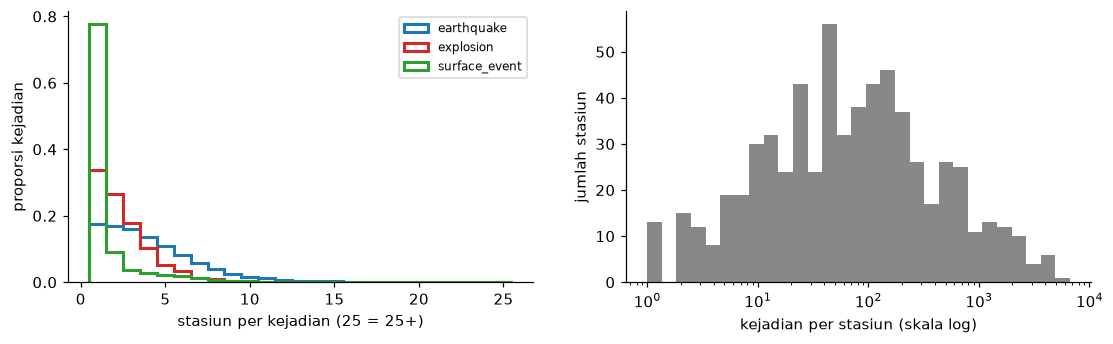

,kejadian,rata2_stasiun,median_stasiun,maks_stasiun,pct_hanya_1_stasiun
label,,,,,
earthquake,39631,4.11,3.0,41,17.5
explosion,6392,2.52,2.0,19,33.7
surface_event,5425,1.64,1.0,16,77.7


,name,network,lat,lon,events,earthquake,explosion,surface_event
563,PB.B201,PB,46.303,-122.265,6658,6142,461,55
173,PB.B203,PB,46.169,-122.334,4887,4400,417,70
454,UW.GNW,UW,47.564,-122.825,4653,4465,188,0
261,UW.HDW,UW,47.648,-123.055,4520,4297,221,2
191,PB.B204,PB,46.136,-122.169,4259,3878,210,171
514,PB.B202,PB,46.245,-122.137,4216,3839,223,154
66,UW.ELK,UW,46.305,-122.342,3637,3505,109,23
289,UW.FL2,UW,46.196,-122.352,3189,2935,187,67
67,UW.DOSE,UW,47.717,-122.972,3004,2894,110,0
153,PB.B941,PB,46.987,-122.219,2763,2649,110,4


In [5]:
deg_ev = e1.groupBy('src', 'label').agg(F.count('*').alias('stations')).toPandas()
deg_st = (e1.groupBy('dst').pivot('label', EVENTS).agg(F.count('*')).fillna(0)
          .join(v2.select(F.col('id').alias('dst'), 'name', 'network', 'lat', 'lon'), 'dst').toPandas())
deg_st['events'] = deg_st[EVENTS].sum(axis=1)

ev_tab = deg_ev.groupby('label').stations.agg(['count', 'mean', 'median', 'max']).loc[EVENTS].round(2)
ev_tab.columns = ['kejadian', 'rata2_stasiun', 'median_stasiun', 'maks_stasiun']
ev_tab['pct_hanya_1_stasiun'] = (deg_ev.groupby('label').stations.apply(lambda s: 100 * (s == 1).mean()).loc[EVENTS]).round(1)
save_md(ev_tab.reset_index(names='kelas'), 'a2_graph_event_degree', 'Jumlah stasiun yang merekam satu kejadian (degree vertex kejadian)')

top = deg_st.nlargest(10, 'events')[['name', 'network', 'lat', 'lon', 'events', *EVENTS]].round(3)
save_md(top, 'a2_graph_top_stations_degree', '10 stasiun yang merekam kejadian terbanyak')

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
for c in EVENTS:
    s = deg_ev.loc[deg_ev.label == c, 'stations'].clip(upper=25)
    axes[0].hist(s, bins=np.arange(.5, 26.5), histtype='step', lw=2, density=True, color=COLORS[c], label=c)
axes[0].set(xlabel='stasiun per kejadian (25 = 25+)', ylabel='proporsi kejadian'); axes[0].legend(fontsize=8)
axes[1].hist(deg_st.events, bins=np.logspace(0, np.log10(deg_st.events.max() + 1), 30), color='#888')
axes[1].set(xscale='log', xlabel='kejadian per stasiun (skala log)', ylabel='jumlah stasiun')
save_fig('a2_graph_degree'); plt.show()
display(ev_tab)
top

- **Gempa terekam paling luas:** rata-rata 4.1 stasiun per kejadian, dan hanya 17.5% yang terekam satu stasiun saja.
- **Surface event paling lokal:** 77.7% hanya terekam **satu stasiun** (rata-rata 1.6). Longsoran dan aliran debris lemah, sehingga hanya stasiun terdekat yang menangkapnya.
- **Ledakan** di tengah (rata-rata 2.5; 33.7% satu stasiun).
- Stasiun tersibuk adalah stasiun borehole PB (B201–B204, sekitar Gunung St. Helens, 46.1–46.3° LU) dan stasiun UW di sekitar Puget Sound. B201 merekam 6,658 kejadian.

### 2. Connected components (G1)
Vertex yang bisa saling dicapai lewat edge membentuk satu komponen. Pertanyaannya: apakah seluruh jaringan stasiun dan kejadian terhubung menjadi satu, atau ada "pulau" yang terpisah?

In [6]:
g1 = GraphFrame(v1, e1)
cc = timed('G1: connected components', lambda: g1.connectedComponents().cache())
comp = (cc.groupBy('component').agg(F.count('*').alias('vertex'), F.sum((F.col('kind') == 'station').cast('int')).alias('stasiun'),
                                     F.sum((F.col('kind') == 'event').cast('int')).alias('kejadian'),
                                     F.concat_ws(', ', F.collect_set('label')).alias('kelas'),
                                     F.concat_ws(', ', F.collect_set('name')).alias('nama_stasiun'))
        .orderBy(F.desc('vertex')).toPandas())
n_v1 = v1.count()
assert comp.vertex.sum() == n_v1
cc_tab = pd.DataFrame({'nilai': {'jumlah komponen': len(comp), 'vertex di komponen terbesar': int(comp.vertex.iloc[0]),
                                  '% vertex di komponen terbesar': round(100 * comp.vertex.iloc[0] / n_v1, 2),
                                  'stasiun di komponen terbesar': int(comp.stasiun.iloc[0])}})
save_md(cc_tab.reset_index(names='ukuran'), 'a2_graph_components', 'Connected components G1')
save_md(comp.iloc[1:].head(15), 'a2_graph_small_components', 'Komponen kecil (selain komponen terbesar)')
display(cc_tab)
comp.iloc[1:].head(15)

,nilai
jumlah komponen,4.00
vertex di komponen terbesar,52084.00
% vertex di komponen terbesar,99.99
stasiun di komponen terbesar,639.00


,component,vertex,stasiun,kejadian,kelas,nama_stasiun
1,910533066761,2,1,1,earthquake,UW.SFER
2,541165879571,2,1,1,explosion,UW.CVILL
3,1228360646887,2,1,1,earthquake,TA.K10A


- G1 hampir **satu kesatuan**: 99.99% vertex (639 dari 642 stasiun) berada dalam satu komponen. Hampir setiap stasiun bisa "dicapai" dari stasiun lain lewat kejadian yang direkam bersama.
- Hanya ada **3 komponen kecil**, masing-masing 1 stasiun + 1 kejadian (UW.SFER, UW.CVILL, TA.K10A): stasiun yang hanya pernah merekam satu kejadian yang tidak direkam stasiun lain.

### 3. PageRank (G2): stasiun paling sentral
PageRank memberi nilai tinggi pada stasiun yang terhubung dengan banyak stasiun yang juga penting. Edge G2 dibuat dua arah karena hubungan "merekam kejadian yang sama" tidak punya arah. Reset probability 0.15, 20 iterasi.

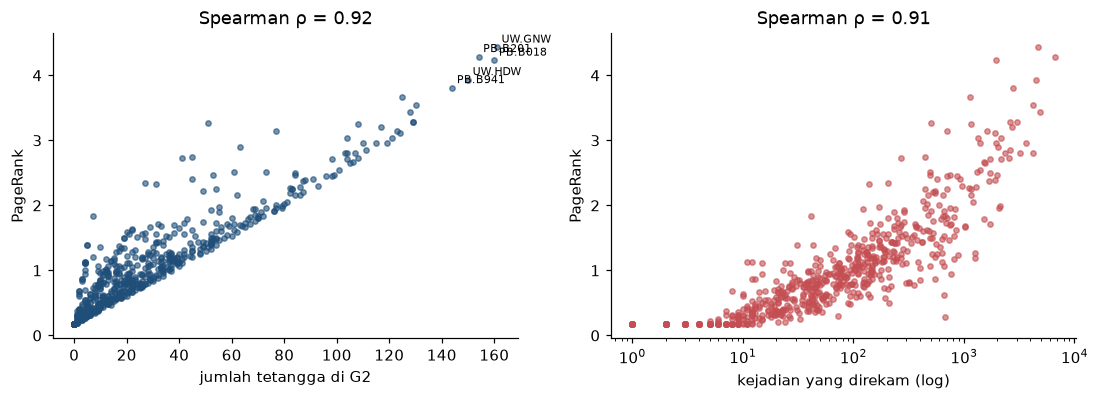

Spearman PageRank vs tetangga: 0.921; PageRank vs kejadian direkam: 0.906


,name,network,lat,lon,pagerank,tetangga,events,peringkat_kejadian
420,UW.GNW,UW,47.564,-122.825,4.433,161.0,4653,3
132,PB.B201,PB,46.303,-122.265,4.288,154.0,6658,1
117,PB.B018,PB,46.980,-123.020,4.232,160.0,1968,23
432,UW.HDW,UW,47.648,-123.055,3.933,150.0,4520,4
139,PB.B941,PB,46.987,-122.219,3.810,144.0,2763,10
479,UW.LTY,UW,47.255,-120.666,3.666,125.0,1130,45
133,PB.B202,PB,46.245,-122.137,3.548,130.0,4216,6
134,PB.B203,PB,46.169,-122.334,3.429,128.0,4887,2
390,UW.DOSE,UW,47.717,-122.972,3.278,129.0,3004,9
114,PB.B013,PB,47.813,-122.911,3.278,129.0,2634,12


In [7]:
g2 = GraphFrame(v2, e2_both)
pr = timed('G2: PageRank', lambda: g2.pageRank(resetProbability=0.15, maxIter=20).vertices.toPandas())
nb = e2.select(F.col('src').alias('id')).union(e2.select(F.col('dst').alias('id'))).groupBy('id').count().withColumnRenamed('count', 'tetangga').toPandas()
pr = pr.merge(nb, on='id', how='left').fillna({'tetangga': 0}).merge(deg_st[['dst', 'events']].rename(columns={'dst': 'id'}), on='id', how='left')
assert pr.pagerank.notna().all()
rho_nb = pr[['pagerank', 'tetangga']].corr(method='spearman').iloc[0, 1]
rho_ev = pr[['pagerank', 'events']].corr(method='spearman').iloc[0, 1]
top_pr = pr.nlargest(10, 'pagerank')[['name', 'network', 'lat', 'lon', 'pagerank', 'tetangga', 'events']].round(3)
top_pr['peringkat_kejadian'] = [int((pr.events > e).sum() + 1) for e in top_pr.events]
save_md(top_pr, 'a2_graph_top_pagerank', f'10 stasiun dengan PageRank tertinggi (G2, bobot ≥ {T})')

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].scatter(pr.tetangga, pr.pagerank, s=12, alpha=.6, color='#1f4e79')
axes[0].set(xlabel='jumlah tetangga di G2', ylabel='PageRank', title=f'Spearman ρ = {rho_nb:.2f}')
axes[1].scatter(pr.events, pr.pagerank, s=12, alpha=.6, color='#c44e52')
axes[1].set(xscale='log', xlabel='kejadian yang direkam (log)', ylabel='PageRank', title=f'Spearman ρ = {rho_ev:.2f}')
for _, r in top_pr.head(5).iterrows():
    axes[0].annotate(r['name'], (r.tetangga, r.pagerank), fontsize=7, xytext=(3, 3), textcoords='offset points')
save_fig('a2_graph_pagerank_vs_degree'); plt.show()
print(f'Spearman PageRank vs tetangga: {rho_nb:.3f}; PageRank vs kejadian direkam: {rho_ev:.3f}')
top_pr

- PageRank sangat sejalan dengan jumlah tetangga (Spearman ρ = 0.92) dan jumlah kejadian (ρ = 0.91). Secara umum, stasiun tersibuk juga paling sentral.
- Pengecualian yang menarik:
  - **PB.B018** (peringkat kejadian ke-23) dan **UW.LTY** (ke-45) masuk 10 besar PageRank. Stasiun ini terhubung dengan banyak stasiun penting di wilayah yang berbeda, yaitu **penghubung (bridge)** jaringan.
  - **UW.LTY** (120.7° BB) berada di timur Pegunungan Cascade, di antara kelompok stasiun barat dan timur Washington.
- Stasiun paling sentral: UW.GNW, PB.B201, PB.B018, UW.HDW, PB.B941, semuanya di Washington barat.

### 4. Komunitas stasiun (Label Propagation, G2)
Setiap stasiun mulai dengan labelnya sendiri, lalu di setiap putaran mengambil label yang paling umum di antara tetangganya. Setelah 10 putaran, stasiun yang terhubung rapat berbagi label yang sama, dan itulah satu **komunitas**.

In [8]:
lp = timed('G2: label propagation', lambda: g2.labelPropagation(maxIter=10).select('id', 'label').toPandas())
st = v2.toPandas().merge(lp, on='id').merge(nb, on='id', how='left').fillna({'tetangga': 0})
assert st.id.is_unique and len(st) == n_st
st['community'] = np.where(st.tetangga == 0, 'terisolasi', st.label.astype(str))
sizes = st[st.community != 'terisolasi'].community.value_counts()
top_c = list(sizes.index[:8])
names = {c: f'K{i + 1}' for i, c in enumerate(top_c)}
st['komunitas'] = [names.get(c, 'terisolasi' if c == 'terisolasi' else 'lainnya') for c in st.community]

rec_c = (e1.groupBy('dst', 'label').agg(F.sum('recordings').alias('n')).toPandas()
         .merge(st[['id', 'komunitas', 'network']].rename(columns={'id': 'dst'}), on='dst'))
mix = rec_c.pivot_table(index='komunitas', columns='label', values='n', aggfunc='sum', fill_value=0)[EVENTS]
mix_pct = (100 * mix.div(mix.sum(axis=1), axis=0)).round(1)
info = st.groupby('komunitas').agg(stasiun=('id', 'size'), lat=('lat', 'mean'), lon=('lon', 'mean'),
                                   jaringan_utama=('network', lambda s: s.value_counts().index[0]))
comm = info.join(mix.sum(axis=1).rename('rekaman')).join(mix_pct.add_prefix('pct_')).round(2)
comm = comm.loc[[*names.values(), *[k for k in ('lainnya', 'terisolasi') if k in comm.index]]]
lp_tab = pd.DataFrame({'nilai': {'jumlah komunitas (≥ 1 tetangga)': len(sizes), 'komunitas dengan ≥ 10 stasiun': int((sizes >= 10).sum()),
                                 'stasiun di 8 komunitas terbesar': int(sizes.iloc[:8].sum()), 'stasiun terisolasi': int((st.community == 'terisolasi').sum())}})
save_md(lp_tab.reset_index(names='ukuran'), 'a2_graph_lpa_summary', 'Ringkasan komunitas (label propagation)')
save_md(comm.reset_index(), 'a2_graph_communities', 'Komunitas stasiun: ukuran, lokasi rata-rata, jaringan utama, komposisi kelas')
display(lp_tab)
comm

,nilai
jumlah komunitas (≥ 1 tetangga),10
komunitas dengan ≥ 10 stasiun,7
stasiun di 8 komunitas terbesar,545
stasiun terisolasi,87


,stasiun,lat,lon,jaringan_utama,rekaman,pct_earthquake,pct_explosion,pct_surface_event
komunitas,,,,,,,,
K1,246,47.74,-122.47,UW,102537,90.2,6.9,2.9
K2,125,45.76,-122.58,UW,62972,84.3,7.2,8.6
K3,61,46.39,-119.26,UW,11304,86.8,12.9,0.4
K4,48,42.89,-123.07,TA,4066,62.7,37.3,0.0
K5,24,43.97,-122.43,UO,2962,53.5,44.2,2.4
K6,22,43.45,-120.86,CC,2468,76.1,6.6,17.4
K7,12,45.21,-120.52,TA,724,97.9,2.1,0.0
K8,7,44.48,-116.74,TA,113,100.0,0.0,0.0
lainnya,10,44.73,-119.24,TA,202,92.1,7.9,0.0


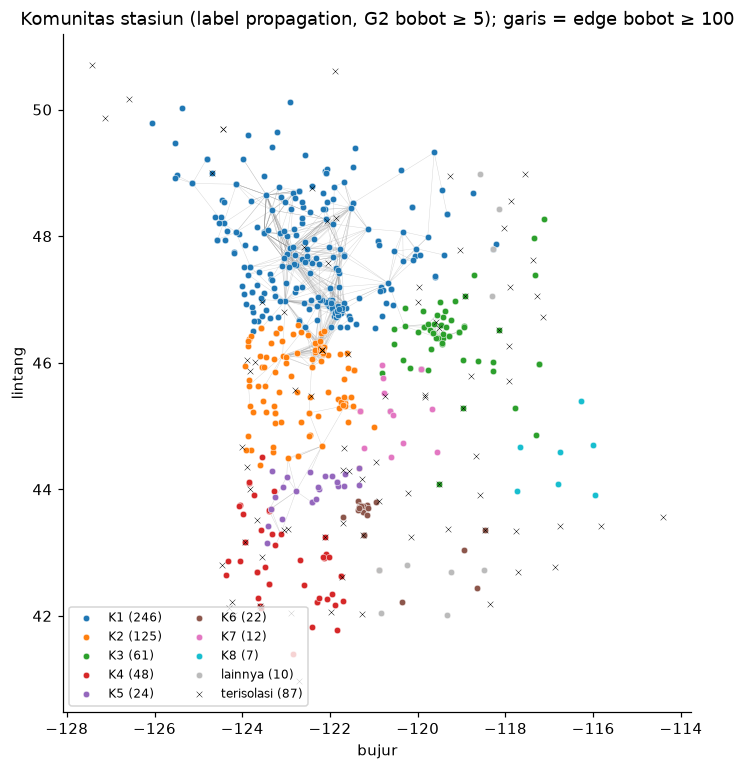

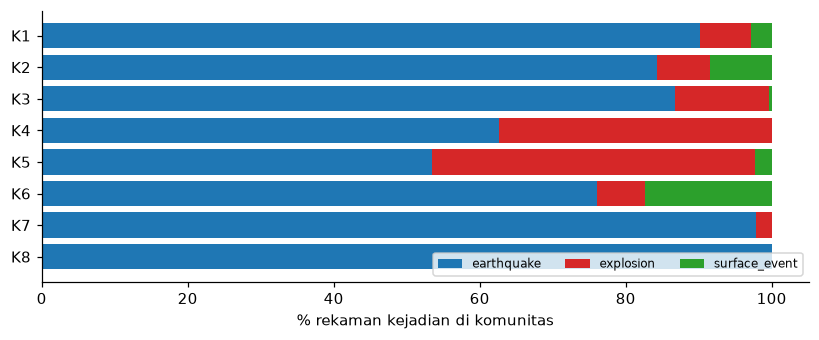

In [9]:
palette = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#17becf']
cmap = {**{n: palette[i] for i, n in enumerate(names.values())}, 'lainnya': '#bbbbbb', 'terisolasi': '#000000'}
xy = st.set_index('id')[['lon', 'lat']]
strong = e2.filter(F.col('weight') >= 100).toPandas()

fig, ax = plt.subplots(figsize=(9, 8))
for s_, d_ in zip(strong.src, strong.dst):
    ax.plot(*zip(xy.loc[s_], xy.loc[d_]), color='#999999', lw=.3, alpha=.4, zorder=1)
for k, g in st.groupby('komunitas'):
    ax.scatter(g.lon, g.lat, s=18 if k != 'terisolasi' else 14, marker='x' if k == 'terisolasi' else 'o',
               color=cmap[k], label=f'{k} ({len(g)})', zorder=2, edgecolor='white' if k != 'terisolasi' else None, linewidth=.3)
ax.set_aspect(1 / np.cos(np.radians(st.lat.mean())))
ax.set(xlabel='bujur', ylabel='lintang', title=f'Komunitas stasiun (label propagation, G2 bobot ≥ {T}); garis = edge bobot ≥ 100')
ax.legend(fontsize=8, loc='lower left', ncols=2)
save_fig('a2_graph_communities_map'); plt.show()

fig, ax = plt.subplots(figsize=(9, 3.2))
plot = mix_pct.loc[[n for n in names.values() if n in mix_pct.index]]
left = np.zeros(len(plot))
for c in EVENTS:
    ax.barh(plot.index, plot[c], left=left, color=COLORS[c], label=c)
    left += plot[c].values
ax.invert_yaxis(); ax.set_xlabel('% rekaman kejadian di komunitas'); ax.legend(fontsize=8, ncols=3, loc='lower right')
save_fig('a2_graph_community_classes'); plt.show()

- Label propagation menemukan **10 komunitas**; 8 terbesar mencakup 545 stasiun. Algoritma **tidak diberi lokasi**, hanya "siapa merekam kejadian yang sama", tetapi komunitasnya **berkelompok secara geografis** di peta. Stasiun yang berdekatan memang mendengar kejadian yang sama.
- **K1** (246 stasiun, Washington barat / Puget Sound) dan **K2** (125, Washington barat daya–Oregon utara, termasuk sekitar St. Helens) adalah inti jaringan, didominasi gempa (90% dan 84%).
- **Komposisi kelas sangat berbeda antar komunitas:**
  - **K5** (Oregon barat tengah, jaringan UO): **44% ledakan**. **K4** (Oregon barat daya, TA): **37% ledakan**.
  - **K6** (Oregon tengah, jaringan **CC** pemantau gunung api): **17% surface event**, tertinggi.
  - **K3** (Washington timur): 13% ledakan.
- Ini memperkuat keputusan Bab 5.1 untuk **tidak memakai lokasi stasiun** sebagai fitur. Jika dipakai, model bisa menebak "ledakan" hanya karena stasiun berada di komunitas K4/K5, bukan karena bentuk sinyalnya.

### 5. Triangle count (G2): seberapa rapat stasiun bertetangga
Segitiga = tiga stasiun yang saling terhubung. **Clustering lokal** = jumlah segitiga ÷ jumlah segitiga yang mungkin, k·(k−1)/2 untuk stasiun dengan k tetangga. Nilai 1 berarti semua tetangga stasiun itu juga saling terhubung.

In [10]:
tc = timed('G2: triangle count', lambda: GraphFrame(v2, e2).triangleCount(StorageLevel.MEMORY_AND_DISK).select('id', 'count').toPandas())
st = st.merge(tc, on='id')
st['clustering'] = np.where(st.tetangga >= 2, st['count'] / (st.tetangga * (st.tetangga - 1) / 2), np.nan)
tri = (st.groupby('komunitas').agg(stasiun=('id', 'size'), segitiga_rata2=('count', 'mean'), clustering_rata2=('clustering', 'mean'))
       .loc[comm.index].round(3))
overall = {'segitiga total (unik)': int(st['count'].sum() // 3), 'clustering rata-rata': round(st.clustering.mean(), 3)}
save_md(tri.reset_index(), 'a2_graph_triangles', 'Triangle count dan clustering lokal per komunitas (G2)')
print(overall)
tri

{'segitiga total (unik)': 83372, 'clustering rata-rata': np.float64(0.69)}


,stasiun,segitiga_rata2,clustering_rata2
komunitas,,,
K1,246,688.626,0.688
K2,125,508.264,0.685
K3,61,168.672,0.688
K4,48,59.292,0.664
K5,24,106.750,0.660
K6,22,49.591,0.702
K7,12,27.583,0.739
K8,7,3.429,0.850
lainnya,10,3.800,0.822


- G2 memiliki **83,372 segitiga** dan **clustering rata-rata 0.69**: kalau stasiun A terhubung dengan B dan C, kemungkinan besar B dan C juga saling terhubung. Jaringan sangat lokal dan rapat, karena stasiun berdekatan merekam kejadian yang sama.
- Clustering serupa di semua komunitas (0.66–0.85). Komunitas kecil di pinggir (K8, lainnya) paling rapat karena anggotanya sedikit dan saling berdekatan.

## Waktu komputasi

In [11]:
tim = pd.DataFrame(timings, columns=['langkah', 'detik'])
save_md(tim, 'a2_graph_timings', 'Waktu setiap langkah graph analytics (Spark local[*], 10 core)')
tim

,langkah,detik
0,G1: bangun & tulis vertex/edge,2.1
1,G2: self-join + hitung bobot,1.1
2,G2: tulis vertex/edge,4.6
3,G1: connected components,56.7
4,G2: PageRank,12.1
5,G2: label propagation,3.6
6,G2: triangle count,4.4


## Ringkasan dan keterbatasan
| | Hasil |
|---|---|
| G1 kejadian–stasiun | 52,090 vertex (51,448 kejadian + 642 stasiun), 187,751 edge |
| G2 stasiun–stasiun | 642 stasiun, 8,637 edge (≥ 5 kejadian bersama), density 0.042 |
| Degree | gempa rata-rata 4.1 stasiun/kejadian; **77.7% surface event hanya terekam 1 stasiun** |
| Connected components | 99.99% vertex dalam satu komponen; 3 komponen kecil (1 stasiun + 1 kejadian) |
| PageRank | paling sentral: UW.GNW, PB.B201, PB.B018; ρ dengan degree 0.92; PB.B018 & UW.LTY sebagai penghubung |
| Komunitas | 10 komunitas yang berkelompok secara geografis; K5/K4 (Oregon) 44%/37% ledakan, K6 (jaringan CC) 17% surface event |
| Triangle | 83,372 segitiga, clustering rata-rata 0.69 |
| Waktu | seluruh algoritma < 1.5 menit di Spark (connected components 57 detik) |

**Insight:**
1. Jaringan PNSN terhubung sebagai satu kesatuan, dengan inti padat di Washington barat.
2. Surface event bersifat sangat lokal: hanya terekam stasiun terdekat.
3. Komunitas stasiun yang ditemukan murni dari pola rekaman ternyata sesuai wilayah, dan tiap wilayah punya komposisi kejadian berbeda (ledakan di Oregon, surface event di jaringan gunung api). Ini bukti bahwa lokasi stasiun akan menjadi jalan pintas bagi model klasifikasi.

**Keterbatasan:**
- Graph dibangun dari metadata (siapa merekam apa), bukan dari isi waveform; noise tidak masuk graph.
- PageRank dan label propagation GraphFrames tidak memakai bobot edge. Bobot hanya dipakai lewat ambang ≥ 5, yang mengisolasi 87 stasiun pinggir (0.2% rekaman).
- Label propagation bisa memberi hasil sedikit berbeda antar-run.
- Nama wilayah komunitas adalah perkiraan dari rata-rata lintang/bujur.

In [12]:
spark.stop()